# IA101 — Notebook 3 — Évaluer un modèle

**Durée : 20 minutes** · Objectif visé : **O4** — évaluer un modèle avec une métrique adaptée

Une exactitude de 90 % peut être excellente ou insuffisante : tout dépend de la répartition des classes et du **coût des erreurs**. Ce notebook utilise un cas de dépistage du cancer du sein, où manquer un cancer est beaucoup plus grave qu'une fausse alerte.

### Plan
1. Les limites de l'exactitude
2. La régression logistique
3. La matrice de confusion
4. Précision et rappel
5. Le seuil de décision

In [1]:
# @title
# Outil de questions de vérification (exécutez cette cellule sans la modifier)
import ipywidgets as widgets
from IPython.display import display, Markdown

def quiz(question, options, bonne, explication):
    """Affiche une question à choix multiples avec rétroaction immédiate."""
    choix = widgets.RadioButtons(options=options, value=None,
                                 layout={"width": "max-content"})
    bouton = widgets.Button(description="Vérifier", button_style="primary")
    sortie = widgets.Output()

    def verifier(_):
        with sortie:
            sortie.clear_output()
            if choix.value is None:
                display(Markdown("Veuillez choisir une réponse."))
            elif choix.value == options[bonne]:
                display(Markdown(f"**Bonne réponse.** {explication}"))
            else:
                display(Markdown("**Réponse incorrecte.** Relisez la section précédente et essayez de nouveau."))

    bouton.on_click(verifier)
    display(Markdown(f"**Question de vérification.** {question}"), choix, bouton, sortie)

In [4]:
# Importations : calcul, visualisation, données, modèles et métriques
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer         # jeu de données sur le cancer du sein
from sklearn.model_selection import train_test_split    # séparation entraînement/test
from sklearn.preprocessing import StandardScaler        # standardisation des variables
from sklearn.pipeline import make_pipeline              # enchaînement du prétraitement et du modèle
from sklearn.linear_model import LogisticRegression     # modèle de classification
from sklearn.dummy import DummyClassifier               # modèle de référence naïf (point de comparaison)
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix, precision_score, recall_score  # évaluation du modèle

# Style des figures : meilleure résolution, sans les bordures du haut et de droite
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
# Chargement des données
donnees = load_breast_cancer()
X = donnees.data
y = 1 - donnees.target          # recodage : 1 = tumeur maligne (classe positive), 0 = bénigne

# Taille du jeu de données et répartition des classes
print(f"{len(y)} tumeurs, {X.shape[1]} variables")
print(f"Malignes : {y.sum()} ({y.mean():.0%}) | Bénignes : {(1 - y).sum()} ({1 - y.mean():.0%})")

# Séparation 75 % entraînement / 25 % test, en conservant la proportion des classes et la reproductibilite
X_ent, X_test, y_ent, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=0)

569 tumeurs, 30 variables
Malignes : 212 (37%) | Bénignes : 357 (63%)


In [11]:
# Convertir X_ent en DataFrame pour utiliser .head() avec les noms de variables
pd.DataFrame(X_ent, columns=donnees.feature_names).head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,14.50,10.89,94.28,640.7,0.11010,0.10990,0.08842,0.05778,0.1856,0.06402,...,15.70,15.98,102.8,745.5,0.13130,0.1788,0.2560,0.12210,0.2889,0.08006
1,12.89,13.12,81.89,515.9,0.06955,0.03729,0.02260,0.01171,0.1337,0.05581,...,13.62,15.54,87.4,577.0,0.09616,0.1147,0.1186,0.05366,0.2309,0.06915
2,19.79,25.12,130.40,1192.0,0.10150,0.15890,0.25450,0.11490,0.2202,0.06113,...,22.63,33.58,148.7,1589.0,0.12750,0.3861,0.5673,0.17320,0.3305,0.08465
3,14.60,23.29,93.97,664.7,0.08682,0.06636,0.08390,0.05271,0.1627,0.05416,...,15.79,31.71,102.2,758.2,0.13120,0.1581,0.2675,0.13590,0.2477,0.06836
4,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,0.1590,0.05648,...,18.98,34.12,126.7,1124.0,0.11390,0.3094,0.3403,0.14180,0.2218,0.07820


In [12]:
# Afficher les 20 premières valeurs de la cible d'entraînement
print("Premières valeurs de y_ent :", y_ent[:20])

# Afficher le nom des classes cibles associées
print("Noms des classes :", donnees.target_names)
print("Note : 1 représente une tumeur maligne, 0 représente une tumeur bénigne.")

Premières valeurs de y_ent : [0 0 1 1 1 0 0 1 0 0 1 0 0 0 0 1 0 0 0 0]
Noms des classes : ['malignant' 'benign']
Note : 1 représente une tumeur maligne, 0 représente une tumeur bénigne.


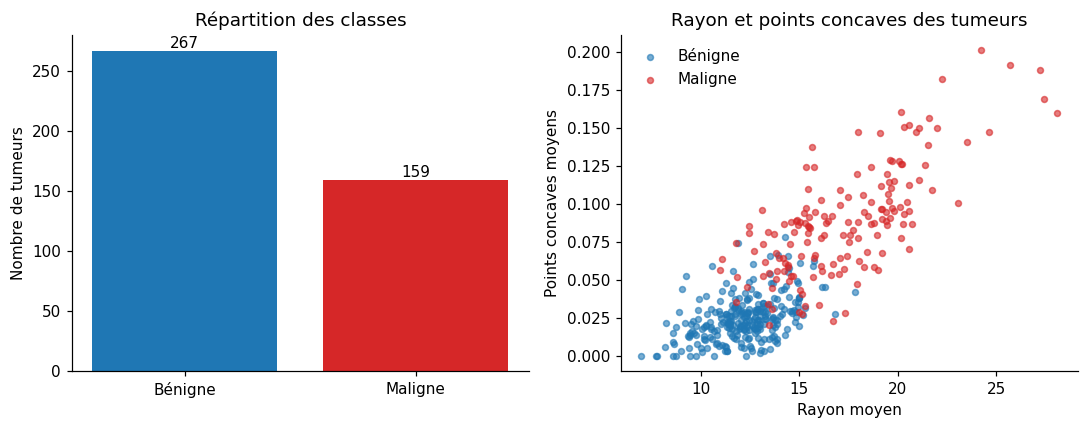

In [6]:
# @title
# Indices des deux variables à afficher
noms = list(donnees.feature_names)
i_rayon = noms.index("mean radius")
i_concavite = noms.index("mean concave points")

etiquettes = ["Bénigne", "Maligne"]
couleurs = ["tab:blue", "tab:red"]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

# Schéma 1 : nombre de tumeurs par classe
barres = ax1.bar(etiquettes, np.bincount(y_ent), color=couleurs)
ax1.bar_label(barres)
ax1.set_title("Répartition des classes")
ax1.set_ylabel("Nombre de tumeurs")

# Schéma 2 : séparation des classes selon deux variables
for classe, (etiquette, couleur) in enumerate(zip(etiquettes, couleurs)):
    masque = y_ent == classe
    ax2.scatter(X_ent[masque, i_rayon], X_ent[masque, i_concavite],
                s=15, alpha=0.6, color=couleur, label=etiquette)
ax2.set_title("Rayon et points concaves des tumeurs")
ax2.set_xlabel("Rayon moyen")
ax2.set_ylabel("Points concaves moyens")
ax2.legend(frameon=False)

plt.tight_layout()
plt.show()

## 1. Les limites de l'exactitude

Pour calculer l'**exactitude** (*accuracy*) d'un modele, on utilise la formule `modele.score(X_test, y_test)`:

$$
\text{Exactitude} = \frac{\text{Nombre de prédictions correctes}}{\text{Nombre total de prédictions}} = \frac{1}{n}\sum_{i=1}^{n} \mathbf{1}(\hat{y}_i = y_i)
$$

où $n$ est le nombre de tumeurs de l'ensemble de test, $y_i$ la vraie classe, $\hat{y}_i$ la classe prédite et $\mathbf{1}(\cdot)$ une fonction qui vaut 1 si la prédiction est correcte et 0 sinon.

Un classifieur trivial comme `DummyClassifier()` prédit toujours la classe majoritaire (« bénin »), sans consulter les variables. Quelle exactitude obtient-il ?

In [5]:
trivial = DummyClassifier(strategy="most_frequent").fit(X_ent, y_ent)
print(f"Exactitude du classifieur trivial : {trivial.score(X_test, y_test):.1%}")
print(f"Tumeurs malignes détectées : {trivial.predict(X_test).sum()} sur {y_test.sum()}")

Exactitude du classifieur trivial : 62.9%
Tumeurs malignes détectées : 0 sur 53


Une exactitude supérieure à 60 % sans détecter **aucune** tumeur maligne. Lorsque les classes sont **déséquilibrées**, l'exactitude seule est trompeuse : il faut analyser le **type** d'erreurs commises.

## 2. La régression logistique

Malgré son nom, la régression logistique est une méthode de **classification**. Elle calcule une combinaison linéaire des variables, $z = w^\top x + b$, puis la transforme en probabilité avec la fonction sigmoïde :

$$P(y = 1 \mid x) = \sigma(z) = \frac{1}{1 + e^{-z}}$$

Ses paramètres $w$ et $b$ sont estimés en minimisant l'**entropie croisée** par une méthode itérative, selon le principe vu au notebook 1. Par défaut, la classe prédite est 1 si la probabilité dépasse **0,5**.

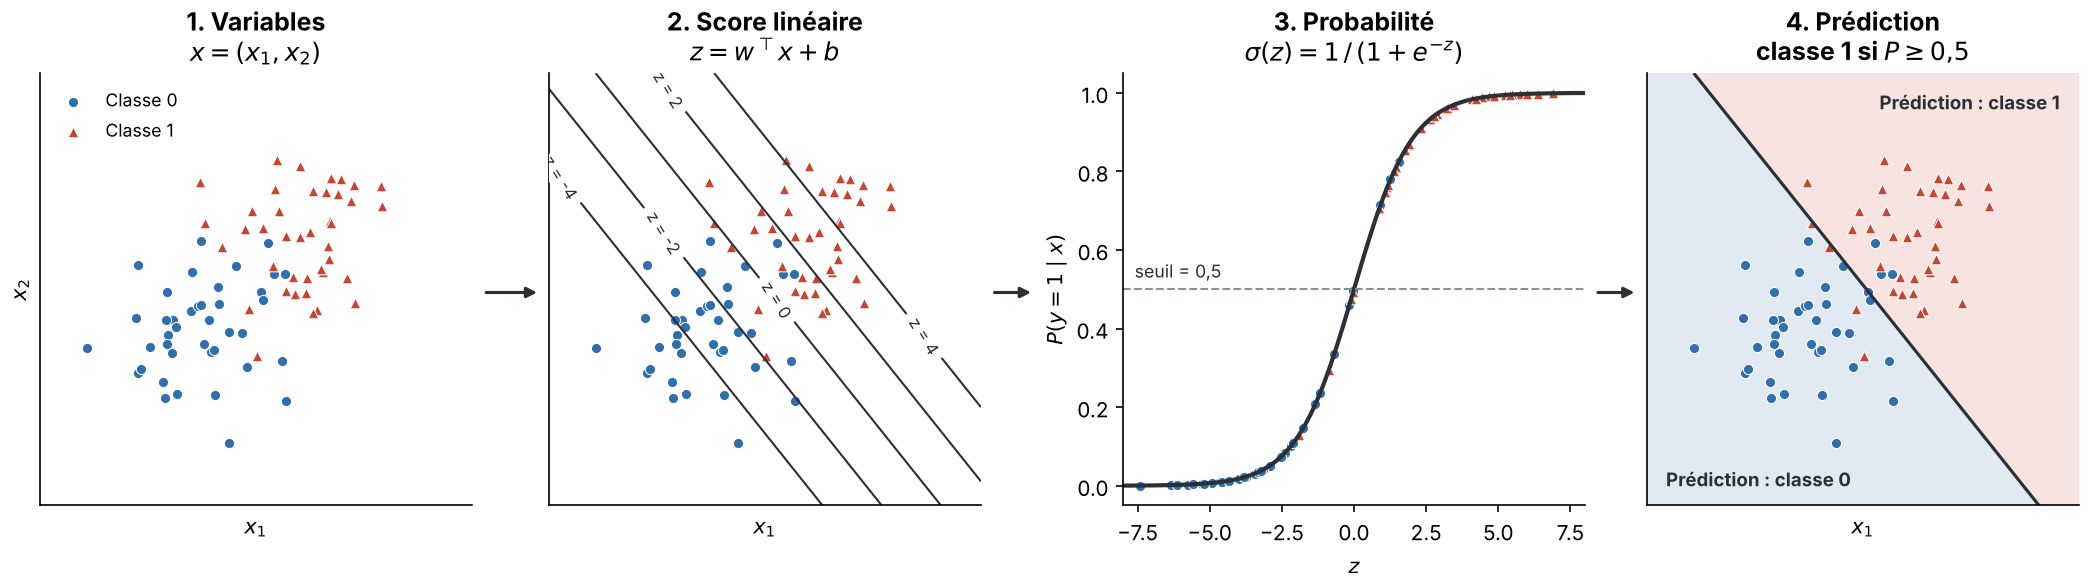

In [13]:
# Pipeline : standardisation des variables, puis régression logistique
# max_iter=1000 : laisse assez d'itérations pour que l'optimisation converge

modele = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))

# Entraînement sur les données d'entraînement uniquement
modele.fit(X_ent, y_ent)

# score : proportion de tumeurs correctement classées dans l'ensemble de test
print(f"Exactitude de la régression logistique : {modele.score(X_test, y_test):.1%}")

Exactitude de la régression logistique : 98.6%


## 3. La matrice de confusion

La **matrice de confusion** est un tableau qui croise les classes réelles et les classes prédites : sa diagonale regroupe les prédictions correctes et ses autres cases montrent les erreurs du modèle, par type.

Pour notre classificateur on a :

| | **Prédit : bénin** | **Prédit : malin** |
| --- | --- | --- |
| **Réel : bénin** | Vrai négatif (VN) | Faux positif (FP) — fausse alerte |
| **Réel : malin** | Faux négatif (FN) — cancer non détecté | Vrai positif (VP) |

**Exactitude (*accuracy*)** : proportion de tumeurs correctement classées.

$$
\text{Exactitude} = \frac{VP + VN}{VP + VN + FP + FN}
$$
où :

- **VP (vrais positifs)** : tumeurs malignes prédites malignes
- **VN (vrais négatifs)** : tumeurs bénignes prédites bénignes
- **FP (faux positifs)** : tumeurs bénignes prédites malignes
- **FN (faux négatifs)** : tumeurs malignes prédites bénignes


Les deux types d'erreurs n'ont pas le même coût :
- un **faux positif** entraîne des examens complémentaires et de l'inquiétude ;
- un **faux négatif** signifie qu'un cancer n'est pas traité.

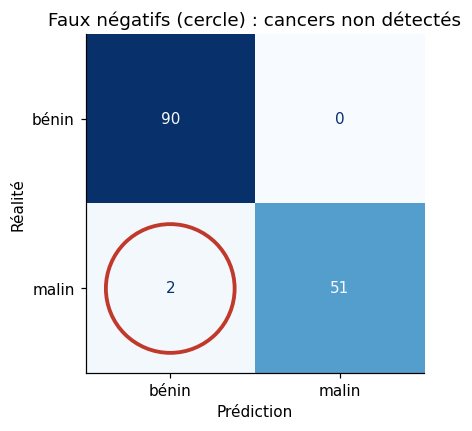

In [19]:
fig, ax = plt.subplots(figsize=(4.8, 4))
ConfusionMatrixDisplay.from_estimator(modele, X_test, y_test, display_labels=["bénin", "malin"],
                                      cmap="Blues", colorbar=False, ax=ax)
ax.set_xlabel("Prédiction"); ax.set_ylabel("Réalité")
ax.add_patch(plt.Circle((0, 1), 0.38, fill=False, color="#c0392b", lw=2.5))
ax.set_title("Faux négatifs (cercle) : cancers non détectés"); plt.show()

**Interprétation de la matrice de confusion**

Sur les 143 tumeurs de l'ensemble de test, le modèle en classe 141 correctement, soit une exactitude de 98,6 %.

- **Faux positifs (0) :** aucune tumeur bénigne n'est prédite maligne, donc la précision est de 51/51 = 100 %. Toutes les alertes du modèle sont justes.
- **Faux négatifs (2) :** 2 tumeurs malignes sur 53 sont prédites bénignes, donc le rappel est de 51/53 = 96,2 %.

Le modèle fait peu d'erreurs, mais ses deux erreurs sont du type le plus grave : une tumeur maligne non détectée peut retarder le diagnostic et le traitement, alors qu'un faux positif entraîne surtout des examens supplémentaires. Dans ce contexte, le **rappel** est donc la métrique à surveiller en priorité, et l'exactitude seule ne suffit pas à évaluer le modèle.

## 4. Précision et rappel

$$\text{Précision} = \frac{VP}{VP + FP} \qquad\qquad \text{Rappel} = \frac{VP}{VP + FN}$$

- **Précision** : parmi les cas signalés positifs, quelle proportion l'est réellement ? (fiabilité des alertes)
- **Rappel** (ou sensibilité) : parmi les cas réellement positifs, quelle proportion est détectée ?

En dépistage, on privilégie généralement un **rappel élevé**.

### Exercice 7 — Calculer la précision et le rappel

In [ ]:
predictions = modele.predict(X_test)
vn, fp, fn, vp = confusion_matrix(y_test, predictions).ravel()
print(f"VN = {vn}, FP = {fp}, FN = {fn}, VP = {vp}")

precision = ...   # À COMPLÉTER
rappel = ...      # À COMPLÉTER

print(f"Précision : {precision:.1%} (scikit-learn : {precision_score(y_test, predictions):.1%})")
print(f"Rappel    : {rappel:.1%} (scikit-learn : {recall_score(y_test, predictions):.1%})")

<details>
<summary><b>Afficher la solution</b> (après avoir fait l'exercice)</summary>

```python
predictions = modele.predict(X_test)
vn, fp, fn, vp = confusion_matrix(y_test, predictions).ravel()
print(f"VN = {vn}, FP = {fp}, FN = {fn}, VP = {vp}")

precision = vp / (vp + fp)
rappel = vp / (vp + fn)

print(f"Précision : {precision:.1%} (scikit-learn : {precision_score(y_test, predictions):.1%})")
print(f"Rappel    : {rappel:.1%} (scikit-learn : {recall_score(y_test, predictions):.1%})")
```

</details>

## 5. Le seuil de décision


Le **seuil de décision** est la valeur de probabilité à partir de laquelle le modèle attribue la classe positive. Il transforme une probabilité en décision :

$$
\hat{y} =
\begin{cases}
1 & \text{si } P(y = 1 \mid x) \geq s \\
0 & \text{sinon}
\end{cases}
$$

Par défaut, $s = 0{,}5$ dans la régression logistique. Par exemple, une tumeur dont la probabilité de malignité est de 0,30 est classée bénigne avec ce seuil, mais maligne avec un seuil de 0,20.

Le seuil n'est pas appris pendant l'entraînement : on peut le modifier sans réentraîner le modèle, et ce choix dépend du coût de chaque type d'erreur.

- **Seuil plus bas :** le modèle détecte davantage de tumeurs malignes, donc moins de faux négatifs, mais il produit plus de fausses alertes. Le rappel augmente en général, et la précision baisse.
- **Seuil plus haut :** le modèle produit moins de fausses alertes, mais il rate davantage de tumeurs malignes. La précision augmente en général, et le rappel baisse.

Le seuil de 0,5 est une convention. En l'**abaissant**, on signale davantage de cas : moins de cancers manqués, mais plus de fausses alertes.

**Prédiction.** Avec un seuil de 0,2, le rappel augmente-t-il ou diminue-t-il ? Et la précision ?

### Exercice 8 — Modifier le seuil

In [ ]:
probas = modele.predict_proba(X_test)[:, 1]   # probabilité estimée de malignité

seuil = 0.2
predictions_seuil = ...   # À COMPLÉTER : 1 si probas >= seuil, 0 sinon

vn, fp, fn, vp = confusion_matrix(y_test, predictions_seuil).ravel()
print(f"Seuil {seuil} : cancers non détectés = {fn} | fausses alertes = {fp}")
print(f"Précision : {precision_score(y_test, predictions_seuil):.1%} | Rappel : {recall_score(y_test, predictions_seuil):.1%}")

<details>
<summary><b>Afficher la solution</b> (après avoir fait l'exercice)</summary>

```python
probas = modele.predict_proba(X_test)[:, 1]

seuil = 0.2
predictions_seuil = (probas >= seuil).astype(int)

vn, fp, fn, vp = confusion_matrix(y_test, predictions_seuil).ravel()
print(f"Seuil {seuil} : cancers non détectés = {fn} | fausses alertes = {fp}")
print(f"Précision : {precision_score(y_test, predictions_seuil):.1%} | Rappel : {recall_score(y_test, predictions_seuil):.1%}")
```

</details>

Dans ce notebook, les deux faux négatifs ont des probabilités de 0,12 et 0,22. Un seuil de 0,10 les ferait donc passer du côté « maligne », mais pourrait aussi créer des faux positifs. Pour rester rigoureux, ce seuil doit être choisi sur des données de validation plutôt que sur l'ensemble de test.

In [ ]:
seuils = np.linspace(0.01, 0.99, 99)
precisions = [precision_score(y_test, (probas >= s).astype(int), zero_division=1) for s in seuils]
rappels = [recall_score(y_test, (probas >= s).astype(int)) for s in seuils]

plt.figure(figsize=(7, 4))
plt.plot(seuils, precisions, lw=2, label="Précision")
plt.plot(seuils, rappels, lw=2, label="Rappel")
plt.axvline(0.5, color="gray", ls="--"); plt.text(0.51, 0.75, "seuil par défaut", color="gray")
plt.axvline(0.2, color="#c0392b", ls="--"); plt.text(0.21, 0.70, "seuil 0,2", color="#c0392b")
plt.xlabel("Seuil de décision"); plt.ylabel("Score"); plt.ylim(0.6, 1.02)
plt.title("Compromis entre précision et rappel"); plt.legend(loc="lower left"); plt.show()

**Discussion (2 minutes).** Quel seuil retiendriez-vous pour un outil de dépistage en clinique ? Et pour un filtre de courriels indésirables, où une fausse alerte fait perdre un message important ?

Il n'existe pas de seuil universel. Le choix dépend du **coût relatif des erreurs** et doit être fait avec les experts du domaine.

In [ ]:
quiz("Un outil de dépistage doit manquer le moins de cas possible. Quelle métrique faut-il surveiller en priorité ?",
     ["La précision", "Le rappel", "L'exactitude"],
     1, "Le rappel mesure la proportion de cas positifs effectivement détectés.")

In [ ]:
quiz("Si l'on abaisse le seuil de décision, en général :",
     ["le rappel augmente et la précision diminue", "le rappel diminue et la précision augmente", "les deux augmentent"],
     0, "Davantage de cas sont signalés : moins de faux négatifs, mais plus de faux positifs.")

## À retenir

- L'**exactitude** est trompeuse lorsque les classes sont déséquilibrées.
- La **matrice de confusion** distingue faux positifs et faux négatifs.
- **Précision** : fiabilité des alertes. **Rappel** : proportion des cas positifs détectés.
- Le **seuil de décision** arbitre entre les deux, en fonction du coût des erreurs dans le contexte d'utilisation.

**Notebook suivant :** 4 — Améliorer un modèle.